<a href="https://colab.research.google.com/github/Limhyojin33/Data-Analysis-with-Open-Source/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_13%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13강 반정형 데이터 분석 : 게시판 글 데이터 활용

### 목표

방송통신대학교 학생 게시판의 글 제목을 수집하고 분석하여, 반정형 데이터의 수집부터 텍스트 분석까지 전체 과정을 실습

### 분석 프로세스 개요

1. 데이터 수집
  - selenium을 활용한 웹 페이지 접근
  - lxml을 이용한 HTML 파싱
  - 게시글 제목 추출

2. 텍스트 데이터 전처리
  - 정규식을 활용한 텍스트 정제
  - 형태소 분석을 통한 명사 추출

3. 키워드 분석
  - 단어 빈도 분석
  - 워드 클라우드 생성
  - 주요 키워드 추출

4. 텍스트 분류 및 시각화
  - LLM을 활용한 텍스트 분류
  - 분류 결과 시각화
  - 인사이트 도출


# 주의 : 런타임 GPU 로 설정 필요

In [ ]:
# LLM 처리를 위한 VLLM 설치 (오래걸리는 작업이므로 미리 실행!)
!pip install vllm
# 필요 시 세션 재시작

In [ ]:
# 한글 처리를 위한 matplotlib 설정 (1)

!sudo apt-get install -y fonts-nanum
!sudo fc-cache –fv
!rm ~/.cache/matplotlib -rf

- 런타임 -> 세션 다시 시작

In [1]:
# 한글 처리를 위한 matplotlib 설정 (2)

import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

# 1. 데이터 수집 및 전처리

## 13-1 웹 스크래핑 라이브러리 설치

In [ ]:
!pip install google-colab-selenium lxml

## 13-2 웹 스크래핑 함수 정의 및 실행

In [3]:
import google_colab_selenium as gs
from lxml import html

## URL로부터 페이지 내용 가져오기
def get_page(driver, url):
    # url 페이지로 이동
    driver.get(url)
    # 해당 페이지의 html을 page_content로 저장
    page_content = driver.page_source
    # page_content를 lxml의 html 객체로 변환하고 tree로 저장
    tree = html.fromstring(page_content)
    return tree

## HTML 트리에서 제목 추출
def extract_titles(tree):
    ## td-subject를 클래스로 가지는 td 태그 > a태그 > string > text() 을 xpath로 구하고 titles로 저장
    titles = tree.xpath('//td[@class="td-subject"]/a/strong/text()')
    return titles

## 제목 목록 출력
def print_titles(titles):
    for title in titles:
        print(title)

## Chrome 드라이버 초기화
driver = gs.Chrome()

## 컴퓨터과학과 게시판 첫번째 페이지 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
tree = get_page(driver, board_url)
titles = extract_titles(tree)
print_titles(titles)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청
2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페
🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!     
연극치료 임상실습 참여자 모집
<<영어연극회 "끼" 47회 정기공연 무료 초대 >>
웹 소설 '연극치료사' 
과제물, 학습자료 가기


## 13-3 다중 페이지 데이터 수집 및 데이터프레임 생성

In [4]:
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
import pandas as pd

## 다음 페이지로 이동하고 tree 정보 반환
def move_to_next_page(driver):
    # _listNext 클래스를 기준으로 엘리먼트 선택
    next_page_link = driver.find_element(By.CLASS_NAME, "_listNext")
    if next_page_link and next_page_link.is_enabled():
        # 다음 페이지 버튼 클릭
        next_page_link.click()
        WebDriverWait(driver, 10).until(
            EC.presence_of_element_located((By.CLASS_NAME, "board-table"))
        )
        page_content = driver.page_source
        tree = html.fromstring(page_content)
        return tree
    else:
        return None

## 여러 페이지에서 게시물 제목 가져오기
def get_board_titles(url, pages, verbose=False):
    driver = gs.Chrome()
    board_titles = []
    for page in pages:
        if verbose:
          print(f"=== 페이지 {page} 처리중입니다. ===")
        if page == 1:
            # 13-2 에서 작성한 get_page 함수를 이용하여 현재 페이지 tree 구하기
            tree = get_page(driver, url)
        else:
            # 다음 페이지로 이동하고 해당 페이지 tree 구하기
            tree = move_to_next_page(driver)
        if tree is not None:
            titles = extract_titles(tree)
            board_titles.extend(titles)
            if verbose:
              print_titles(titles)
    driver.quit()  # Chrome 드라이버 종료
    return board_titles

## 컴퓨터과학과 게시판 1 페이지 ~ 10 페이지의 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=True)
## 컴퓨터과학과 제목 데이터프레임 생성
cs_df = pd.DataFrame(data = {'제목': board_titles})

<IPython.core.display.Javascript object>

=== 페이지 1 처리중입니다. ===
[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청
2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페
🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!     
연극치료 임상실습 참여자 모집
<<영어연극회 "끼" 47회 정기공연 무료 초대 >>
웹 소설 '연극치료사' 
과제물, 학습자료 가기
=== 페이지 2 처리중입니다. ===
●동우회/서울남부● 누구나 쉬운~피클볼, 파크골프, 양궁, 건강체조, 그외~
「SK쉴더스 Rookies 7기」 교육과정
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
미래내일 일경험 기업 실무 프로젝트 참여자 모집 (~9/20)
2026 AI 트렌드 온라인 특강
🚨🚨방통대. 방송대학생들 다 모였다! 국내 최대 온라인 학생 커뮤니티 사이트🚨🚨
방송대 모든 학과 과제&기출 창고
창작과 공연을 이어가는 연극동아리에서 회원을 모집합니다.
📢오랜 전통의 극예술연구회에서 신입 회원을 모집합니다🎵
=== 페이지 3 처리중입니다. ===
●동우회/서울남부● 누구나 쉬운~피클볼, 파크골프, 양궁, 건강체조, 그외~
「SK쉴더스 Rookies 7기」 교육과정
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
미래내일 일경험 기업 실무 프로젝트 참여자 모집 (~9/20)
2026 AI 트렌드 온라인 특강
🚨🚨방통대. 방송대학생들 다 모였다! 국내 최대 온라인 학생 커뮤니티 사이트🚨🚨
방송대 모든 학과

# 2. 텍스트 데이터 전처리

## 13-4 정규식을 활용한 텍스트 정제

In [5]:
import re

## 텍스트 정제 함수
def clean_text(text):
    if isinstance(text, str):
        # 특수 문자 제거 regex (영어 소문자, 영어 대문자, 숫자, 한글, 공백글자만 허용)
        text = re.sub(r'[^a-zA-Z0-9가-힣\s]', '', text)
        # HTML 태그 제거 regex
        text = re.sub(r'<[^>]*>', '', text)
        # 소문자로 변환 python 함수
        text = text.lower()
        return text
    else:
        return ""

## 데이터프레임 정제 함수
def clean_df(df):
  if not df.empty:
      df['정제된 제목'] = df['제목'].apply(clean_text)

## cs_df에 정제 함수 적용
clean_df(cs_df)
cs_df

,제목,정제된 제목
0,"[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청",인권센터 아차 싶다 그때 그 말 괜찮은 줄 알았는데 인천지역대학 특강 신청
1,2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페,2026학년도 2학기 기말시험 시행 공고 크로바 기출문제 카페
2,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방
3,📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를,우수 학습자 인터뷰 영상온라인 강의 노하우 팁왜 공부해요방진이방송대를
4,🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔,방송대 공지사항 카톡 알리미과제길잡이기출과제과제족보기출문제요점정리
...,...,...
95,[KISIA] 2026 정보보호 정책제안 공모전,kisia 2026 정보보호 정책제안 공모전
96,연극치료 임상실습 대상자 모집중 입니다.,연극치료 임상실습 대상자 모집중 입니다
97,웹 소설 '연극치료사',웹 소설 연극치료사
98,"7월 24일~25일 연극 ""시간이 지나도"" 무료 관람. 본교열린관지하소극",7월 24일25일 연극 시간이 지나도 무료 관람 본교열린관지하소극


## 13-5 형태소 분석기 설치 및 실행 예시

In [ ]:
## Kiwi 형태소 분석기 설치
!pip install kiwipiepy

In [8]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')

## 문장 형태소 분석 결과 출력
kiwi.analyze('안녕하세요 저는 방송대 학생입니다.')[0][0]

[Token(form='안녕', tag='NNG', start=0, len=2),
 Token(form='하', tag='XSA', start=2, len=1),
 Token(form='세요', tag='EF', start=3, len=2),
 Token(form='저', tag='NP', start=6, len=1),
 Token(form='는', tag='JX', start=7, len=1),
 Token(form='방송대', tag='NNP', start=9, len=3),
 Token(form='학생', tag='NNG', start=13, len=2),
 Token(form='이', tag='VCP', start=15, len=1),
 Token(form='ᆸ니다', tag='EF', start=15, len=3),
 Token(form='.', tag='SF', start=18, len=1)]

## 13-6 형태소 분석을 통한 품사 분리

In [10]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')
kiwi.add_user_word('방통대', 'NNP')

## 텍스트 형태소 분석 함수
def analyze_morphemes(text):
    if isinstance(text, str):
       result = kiwi.analyze(text)

       morphemes = []
       for token in result[0][0]:
            ## 형태소(form)와 품사(tag) 정보를 튜플로 morphemes에 추가
            morphemes.append((token.form, token.tag))
       return morphemes
    else:
        return []

## 데이터프레임에 형태소 분석 적용 함수
def pos_df(df):
  if not df.empty:
        # `정제된 제목` 칼럼의 값에 analyze_morphemes 함수를 적용하고 결과를 `행태소 분석 결과` 칼럼에 저장
        df['형태소 분석 결과'] = df['정제된 제목'].apply(analyze_morphemes)

## 형태소 분석 적용
pos_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과
0,"[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청",인권센터 아차 싶다 그때 그 말 괜찮은 줄 알았는데 인천지역대학 특강 신청,"[(인권, NNG), (센터, NNG), (아차, IC), (싶, VX), (다, ..."
1,2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페,2026학년도 2학기 기말시험 시행 공고 크로바 기출문제 카페,"[(2026, SN), (학년도, NNG), (2, SN), (학기, NNG), (..."
2,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)..."
3,📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를,우수 학습자 인터뷰 영상온라인 강의 노하우 팁왜 공부해요방진이방송대를,"[(우수, NNG), (학습자, NNG), (인터뷰, NNG), (영상, NNG),..."
4,🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔,방송대 공지사항 카톡 알리미과제길잡이기출과제과제족보기출문제요점정리,"[(방송대, NNP), (공지, NNG), (사항, NNG), (카톡, NNP), ..."
...,...,...,...
95,[KISIA] 2026 정보보호 정책제안 공모전,kisia 2026 정보보호 정책제안 공모전,"[(kisia, SL), (2026, SN), (정보, NNG), (보호, NNG)..."
96,연극치료 임상실습 대상자 모집중 입니다.,연극치료 임상실습 대상자 모집중 입니다,"[(연극치료, NNP), (임상, NNG), (실습, NNG), (대상자, NNG)..."
97,웹 소설 '연극치료사',웹 소설 연극치료사,"[(웹, NNG), (소설, NNG), (연극, NNG), (치료사, NNG)]"
98,"7월 24일~25일 연극 ""시간이 지나도"" 무료 관람. 본교열린관지하소극",7월 24일25일 연극 시간이 지나도 무료 관람 본교열린관지하소극,"[(7, SN), (월, NNB), (24, SN), (일, NNB), (25, S..."


## 13-7 명사 추출

In [12]:
## 형태소 분석 결과에서 명사 추출
def extract_nouns(morphemes):
    # 형태소가 NNG (일반명사), NNP (고유명사) 인 word를 nouns에 저장
    nouns = [word for word, tag in morphemes if tag in ['NNG', 'NNP']]
    return nouns

## 데이터프레임에 명사 추출 적용
def noun_df(df):
  if not df.empty:
      df['명사'] = df['형태소 분석 결과'].apply(extract_nouns)

## 명사 추출 적용
noun_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과,명사
0,"[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청",인권센터 아차 싶다 그때 그 말 괜찮은 줄 알았는데 인천지역대학 특강 신청,"[(인권, NNG), (센터, NNG), (아차, IC), (싶, VX), (다, ...","[인권, 센터, 그때, 말, 인천, 지역, 대학, 특강, 신청]"
1,2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페,2026학년도 2학기 기말시험 시행 공고 크로바 기출문제 카페,"[(2026, SN), (학년도, NNG), (2, SN), (학기, NNG), (...","[학년도, 학기, 기말, 시험, 시행, 공고, 크로바, 기출, 문제, 카페]"
2,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)...","[크로바, 네이버, 카페, 크로바, 기출, 문제, 카페, 크로바, 학사, 공지, 전..."
3,📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를,우수 학습자 인터뷰 영상온라인 강의 노하우 팁왜 공부해요방진이방송대를,"[(우수, NNG), (학습자, NNG), (인터뷰, NNG), (영상, NNG),...","[우수, 학습자, 인터뷰, 영상, 온라인, 강의, 노하우, 팁, 공부, 방, 진, ..."
4,🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔,방송대 공지사항 카톡 알리미과제길잡이기출과제과제족보기출문제요점정리,"[(방송대, NNP), (공지, NNG), (사항, NNG), (카톡, NNP), ...","[방송대, 공지, 사항, 카톡, 알리미과제길잡이기출과제과제족보, 기출, 문제, 요점..."
...,...,...,...,...
95,[KISIA] 2026 정보보호 정책제안 공모전,kisia 2026 정보보호 정책제안 공모전,"[(kisia, SL), (2026, SN), (정보, NNG), (보호, NNG)...","[정보, 보호, 정책, 제안, 공모전]"
96,연극치료 임상실습 대상자 모집중 입니다.,연극치료 임상실습 대상자 모집중 입니다,"[(연극치료, NNP), (임상, NNG), (실습, NNG), (대상자, NNG)...","[연극치료, 임상, 실습, 대상자, 모집]"
97,웹 소설 '연극치료사',웹 소설 연극치료사,"[(웹, NNG), (소설, NNG), (연극, NNG), (치료사, NNG)]","[웹, 소설, 연극, 치료사]"
98,"7월 24일~25일 연극 ""시간이 지나도"" 무료 관람. 본교열린관지하소극",7월 24일25일 연극 시간이 지나도 무료 관람 본교열린관지하소극,"[(7, SN), (월, NNB), (24, SN), (일, NNB), (25, S...","[연극, 시간, 무료, 관람, 본교열린관지하소극]"


## 13-8 데이터 전처리 통합 함수 정의

In [13]:
## 데이터프레임 전처리 통합 함수
def preprocessing_df(df):
  clean_df(df) ## 텍스트 정제 적용
  pos_df(df) ## 형태소 분석 적용
  noun_df(df) ## 명사 추출 적용

# 3. 키워드 분석

## 13-9 단어 빈도 계산

In [14]:
from collections import Counter

## 데이터프레임에서 단어 빈도 계산
def get_word_count(df):
    if not df.empty:
        # 모든 명사의 리스트를 구함
        all_nouns = df['명사'].sum()
        # 모든 명사들에 대한 Counter 객체(빈도 정보) 를 반환
        return Counter(all_nouns)

## cs_df의 단어 빈도 계산
word_count = get_word_count(cs_df)
print("단어 빈도:")
## 상위 30개 단어(most_common)의 빈도 출력
for word, freq in word_count.most_common(30):
    print(f"{word}: {freq}")

단어 빈도:
모집: 35
연극: 29
회원: 24
동아리: 22
신입: 21
기출: 16
문제: 16
카페: 16
방송대: 16
네이버: 14
정리: 13
기: 13
대표: 13
요점: 11
참고: 11
극예술: 10
연구회: 10
학기: 8
공지: 8
온라인: 8
사항: 8
교재: 8
장터: 8
극예술연구회: 8
인터뷰: 7
공부: 7
카톡: 7
웹: 7
소설: 7
치료사: 7


## 13-10 워드클라우드 생성 및 시각화

In [ ]:
## WordCloud 라이브러리 설치
!pip install wordcloud

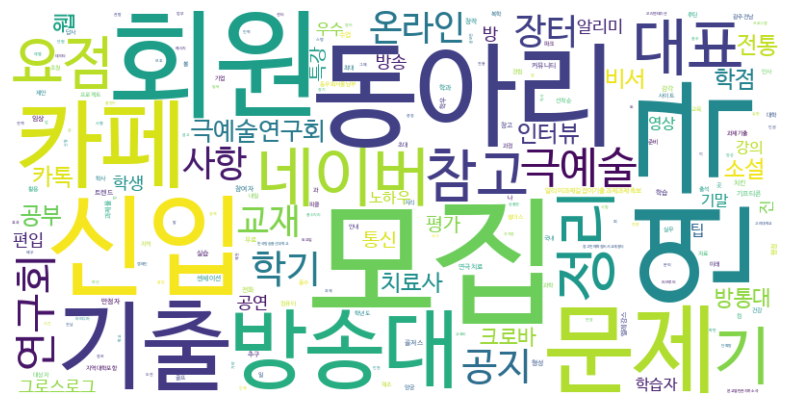

In [18]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

## 단어 빈도를 바탕으로 워드클라우드 생성 및 표시
def plot_wordcloud(word_count):
    ## 워드 클라우드 생성
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='viridis',
        font_path='/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf' ## 한글 폰트 경로 지정
        ).generate_from_frequencies(word_count)# word_count의 빈도 정보를 이용하여 생성

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear') ## 이미지 표시
    plt.axis("off") ## 축 비활성화
    plt.show() ## 그래프 표시

## cs_df에서 단어 빈도 계산
word_count = get_word_count(cs_df)
## 워드클라우드 생성 및 표시
plot_wordcloud(word_count)

## 13-11 다른 학과의 워드 클라우드 생성

<IPython.core.display.Javascript object>

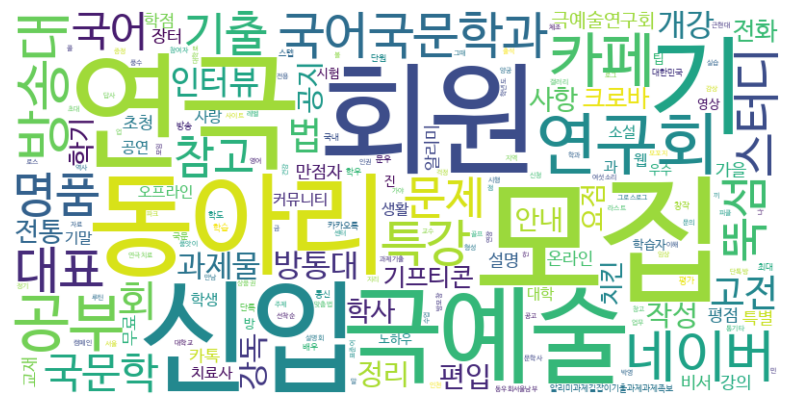

In [19]:
board_name = '국어국문학과'
board_url = 'https://korean.knou.ac.kr/korean/5323/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
ko_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(ko_df)
word_count = get_word_count(ko_df)
plot_wordcloud(word_count)

<IPython.core.display.Javascript object>

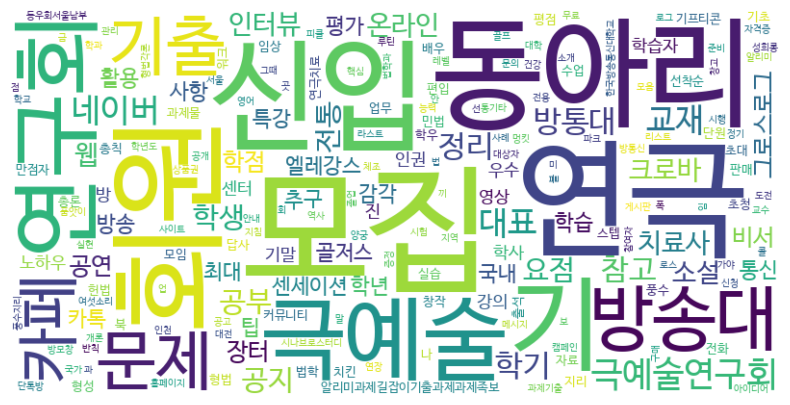

In [20]:
board_name = '법학과'
board_url = 'https://law.knou.ac.kr/law/5176/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
law_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(law_df)
word_count = get_word_count(law_df)
plot_wordcloud(word_count)

# 4. 텍스트 분류 및 시각화

## 13-12 VLLM 라이브러리 설치 및 LLM 모델 로드

주의
- 런타임 유형 : GPU
- 라이브러리 설치 및 모델 다운로드에 수 분(>6분)의 시간이 소요됩니다.


In [ ]:
from vllm import LLM

## LLM 모델 로드 및 설정
llm = LLM(
    model="LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct",
    tensor_parallel_size=1,
    dtype="half",
    gpu_memory_utilization=0.6,
    max_model_len=32000,
    trust_remote_code=True
)

## 13-13 LLM 샘플링 파라미터 설정 및 프롬프트 생성

In [24]:
from vllm import SamplingParams ## SamplingParams 클래스 임포트

## 샘플링 파라미터 설정
sampling_params = SamplingParams(
    temperature=0.3, ## 생성 텍스트의 다양성 조절
    top_p=1.0, ## top_p 누적 확률 내에서 토큰 샘플링
    max_tokens=512, ## 생성될 최대 토큰 수
    frequency_penalty=0.5 ## 자주 나타나는 토큰에 대한 패널티
)

def format_prompt(user_input: str) -> str:
    ## 프롬프트 형식화 함수
    messages = [
        {"role": "system", "content": "Yor are EXAONE model from LG AI Research, a helpful-assistant."},
        {"role": "user", "content": user_input}
    ]
    return messages

## 프롬프트 생성
prompt = format_prompt("대한민국의 수도는 어디인가요? 수도에 여행하러간다면 어떤 즐길거리가 있을까요?")

## LLM을 사용하여 텍스트 생성
# chat 함수를 이용 (프롬프트와 샘플링 파라미터)
outputs = llm.chat(prompt, sampling_params)

## 생성된 텍스트 출력
print("\n생성된 텍스트:", outputs[0].outputs[0].text)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:08<00:00,  8.50s/it, est. speed input: 7.06 toks/s, output: 39.30 toks/s]


생성된 텍스트: 대한민국의 수도는 **서울**입니다. 서울은 역사와 현대가 공존하는 매력적인 도시로, 다양한 관광 명소와 즐길거리를 제공합니다:

1. **경복궁**: 조선 시대의 궁궐로, 아름다운 건축물과 정원을 감상할 수 있습니다. 특히 봄에는 벚꽃이 만발해 더욱 아름답습니다.

2. **인사이트 타워**: 서울스카이에서 제공하는 전망대에서 서울 시내 전경을 한눈에 볼 수 있습니다. 야간에도 개방되어 야경 감상이 가능합니다.

3. **국립중앙박물관**: 한국의 역사와 문화를 한눈에 볼 수 있는 곳으로, 고대 유물부터 현대 작품까지 폭넓게 전시되어 있습니다.

4. **한강공원**: 한강을 따라 걷거나 자전거를 타며 자연을 즐기거나 피크닉을 즐길 수 있습니다. 특히 가을이면 단풍이 아름다워 많은 사람들이 찾습니다.

5. **명동 및 홍대**: 쇼핑과 문화 체험을 즐기기에 좋은 지역입니다. 명동은 전통 시장부터 고급 쇼핑몰까지 다양한 경험을 제공하고, 홍대는 젊은 문화와 예술 활동으로 유명합니다.

6. **롯데월드타워 (서울스카이)**: 서울의 랜드마크 중 하나로, 전망대에서 서울 시내를 조망할 수 있으며 다양한 레스토랑과 엔터테인먼트 시설도 이용 가능합니다.

이러한 장소들은 서울의 역사적 가치와 현대적인 면모를 동시에 체험할 수 있게 해줍니다. 여행 계획 시 계절과 관심사에 맞게 선택하시면 더욱 풍성한 경험이 될 것입니다!


## 13-14 LLM 기반 분류 프롬프트 및 함수 정의

In [25]:
## 분류 프롬프트 형식화 함수
def format_classifier_prompt(board_title, title) -> str:
    messages = [
        {"role": "system", "content": "You are EXAONE model from LG AI Research, a helpful assistant."},
        {"role": "user", "content": """주어진 글의 제목을 분류하는 AI 모델입니다.
분류 클래스는 학사/전공, 학생활동, 외부정보로 나뉘어집니다.
- 학사/전공: 교재, 과제, 시험 등 학업 및 전공 관련 내용
- 학생활동: 동아리, 스터디, 모임 등 학생들의 자발적 활동
- 외부정보: 취업, 공모전, 행사 등 외부 정보"""},
        {"role": "user", "content": """예시)
전공명: 컴퓨터학과, 제목: 프로그래밍 과제 질문 -> 학사/전공
전공명: 컴퓨터학과, 제목: 알고리즘 스터디 모집 -> 학생활동
전공명: 컴퓨터학과, 제목: IT 취업 박람회 -> 외부정보"""},
        {"role": "user", "content": f"전공명: {board_title}\n제목: {title}"}
    ]
    return messages

## 분류 수행 함수
def classify(major, title):
    prompt = format_classifier_prompt(major, title) ## 분류 프롬프트 생성
    outputs = llm.chat([prompt], sampling_params) ## LLM으로 분류 실행
    return outputs[0].outputs[0].text ## 분류 결과 텍스트 반환

In [26]:
classify('컴퓨터학과', '딥러닝 개발 중에 질문 있습니다.')

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.78s/it, est. speed input: 109.39 toks/s, output: 41.73 toks/s]


'제목: **딥러닝 개발 중에 질문 있습니다.**\n\n**분류:** 학사/전공\n\n**설명:** 이 제목은 딥러닝이라는 특정 학문 분야의 기술적인 내용과 관련된 질문을 다루고 있어 학업 및 전공 관련 내용에 해당하므로 **학사/전공** 분류에 속합니다.'

In [27]:
classify('컴퓨터학과', '연극 동아리 회원 모집!! 신규 단원 혜택! AI로 배우는 연극!')

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.49s/it, est. speed input: 133.34 toks/s, output: 42.88 toks/s]


'**분류 결과:** 학생활동  \n**설명:** 제목이 연극 동아리의 회원 모집과 관련된 내용을 다루고 있으며, 특히 "AI로 배우는 연극!" 부분은 학생들의 자발적인 활동과 관련된 요소를 포함하고 있어 학생활동 범주에 속합니다.'

## 13-15 분류 결과 파싱 함수 정의

In [28]:
def get_class(analysis_result):
    ## 분석 결과에서 분류 클래스 추출
    classes = ['학사/전공', '학생활동', '외부정보', '기타']
    classes_index = [analysis_result.find(cls) for cls in classes]

    min_index = float('inf')
    min_class = '기타'

    for i in range(len(classes)):
        current_index = classes_index[i]
        if current_index != -1 and current_index < min_index:
            min_index = current_index
            min_class = classes[i]

    return min_class

In [29]:
## 컴퓨터과학과 제목 분류 헬퍼 함수 정의
def classify_cs(title):
  return classify('컴퓨터과학과', title)

## '제목' 컬럼에 분류 함수 적용하여 분석 결과 저장
cs_df['class_analysis'] = cs_df['제목'].apply(classify_cs)
## 분석 결과에서 최종 분류 클래스 추출하여 저장
cs_df['class'] = cs_df['class_analysis'].apply(get_class)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.36s/it, est. speed input: 90.35 toks/s, output: 42.84 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.90s/it, est. speed input: 107.39 toks/s, output: 43.69 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

...

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.37s/it, est. speed input: 81.10 toks/s, output: 43.09 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  5.52it/s, est. speed input: 1192.84 toks/s, output: 39.38 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  4.86it/s, est. speed input: 981.65 toks/s, output: 39.26 toks/s]


In [30]:
cs_df

,제목,정제된 제목,형태소 분석 결과,명사,class_analysis,class
0,"[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청",인권센터 아차 싶다 그때 그 말 괜찮은 줄 알았는데 인천지역대학 특강 신청,"[(인권, NNG), (센터, NNG), (아차, IC), (싶, VX), (다, ...","[인권, 센터, 그때, 말, 인천, 지역, 대학, 특강, 신청]","**분류 결과:** 외부정보\n\n**설명:** 제목에서 ""인권센터""와 관련된 특강...",외부정보
1,2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페,2026학년도 2학기 기말시험 시행 공고 크로바 기출문제 카페,"[(2026, SN), (학년도, NNG), (2, SN), (학기, NNG), (...","[학년도, 학기, 기말, 시험, 시행, 공고, 크로바, 기출, 문제, 카페]","**분류 결과:** 학사/전공 \n**설명:** 제목이 ""2026학년도 2학기 기...",학사/전공
2,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)...","[크로바, 네이버, 카페, 크로바, 기출, 문제, 카페, 크로바, 학사, 공지, 전...",제목: 🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방\...,학사/전공
3,📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를,우수 학습자 인터뷰 영상온라인 강의 노하우 팁왜 공부해요방진이방송대를,"[(우수, NNG), (학습자, NNG), (인터뷰, NNG), (영상, NNG),...","[우수, 학습자, 인터뷰, 영상, 온라인, 강의, 노하우, 팁, 공부, 방, 진, ...","제목: **""우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢...",학생활동
4,🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔,방송대 공지사항 카톡 알리미과제길잡이기출과제과제족보기출문제요점정리,"[(방송대, NNP), (공지, NNG), (사항, NNG), (카톡, NNP), ...","[방송대, 공지, 사항, 카톡, 알리미과제길잡이기출과제과제족보, 기출, 문제, 요점...",제목: **학사/전공**\n\n**설명:**\n이 제목은 컴퓨터과학과 학생들의 학업...,학사/전공
...,...,...,...,...,...,...
95,[KISIA] 2026 정보보호 정책제안 공모전,kisia 2026 정보보호 정책제안 공모전,"[(kisia, SL), (2026, SN), (정보, NNG), (보호, NNG)...","[정보, 보호, 정책, 제안, 공모전]","제목: ""[KISIA] 2026 정보보호 정책제안 공모전""\n\n**분류:** 외부정보",외부정보
96,연극치료 임상실습 대상자 모집중 입니다.,연극치료 임상실습 대상자 모집중 입니다,"[(연극치료, NNP), (임상, NNG), (실습, NNG), (대상자, NNG)...","[연극치료, 임상, 실습, 대상자, 모집]","제목: ""연극치료 임상실습 대상자 모집중 입니다.""\n\n**분류:** 학생활동 ...",학생활동
97,웹 소설 '연극치료사',웹 소설 연극치료사,"[(웹, NNG), (소설, NNG), (연극, NNG), (치료사, NNG)]","[웹, 소설, 연극, 치료사]",제목: **웹 소설 '연극치료사'** 에 대한 분류는 다음과 같습니다:\n\n- *...,외부정보
98,"7월 24일~25일 연극 ""시간이 지나도"" 무료 관람. 본교열린관지하소극",7월 24일25일 연극 시간이 지나도 무료 관람 본교열린관지하소극,"[(7, SN), (월, NNB), (24, SN), (일, NNB), (25, S...","[연극, 시간, 무료, 관람, 본교열린관지하소극]",**분류:** 외부정보,외부정보


## 13-17 분류 결과 시각화

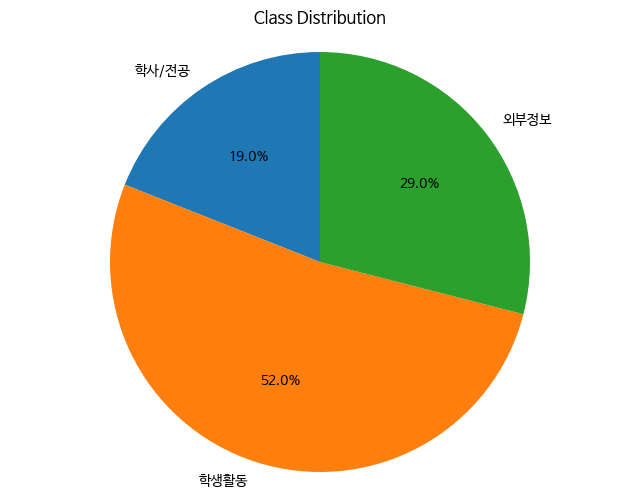

In [31]:
def plot_class(df):
  ## 분류 클래스별 개수 계산 및 순서 재정렬
  class_counts = df['class'].value_counts().reindex(['학사/전공', '학생활동', '외부정보'])

  plt.figure(figsize=(8, 6)) ## 그래프 크기 설정
  plt.pie(class_counts,
          labels=class_counts.index,
          autopct='%.1f%%', ## 퍼센트 표시 형식
          startangle=90, ## 시작 각도 설정
          )

  plt.title('Class Distribution') ## 그래프 제목 설정
  plt.axis('equal') ## 원형 비율 유지
  plt.show() ## 그래프 표시

plot_class(cs_df)

## 13-18 다른 학과의 분류 결과 시각화

In [32]:
def classify_ko(title):
  return classify('국어국문학과', title)

ko_df['class_analysis'] = ko_df['제목'].apply(classify_ko)
ko_df['class'] = ko_df['class_analysis'].apply(get_class)

def classify_law(title):
  return classify('법학과', title)

law_df['class_analysis'] = law_df['제목'].apply(classify_law)
law_df['class'] = law_df['class_analysis'].apply(get_class)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.21s/it, est. speed input: 171.67 toks/s, output: 42.09 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.40s/it, est. speed input: 151.06 toks/s, output: 43.67 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

...

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.54s/it, est. speed input: 76.78 toks/s, output: 42.92 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.87s/it, est. speed input: 106.18 toks/s, output: 42.90 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  1.95it/s, est. speed input: 365.54 toks/s, output: 43.00 toks/s]


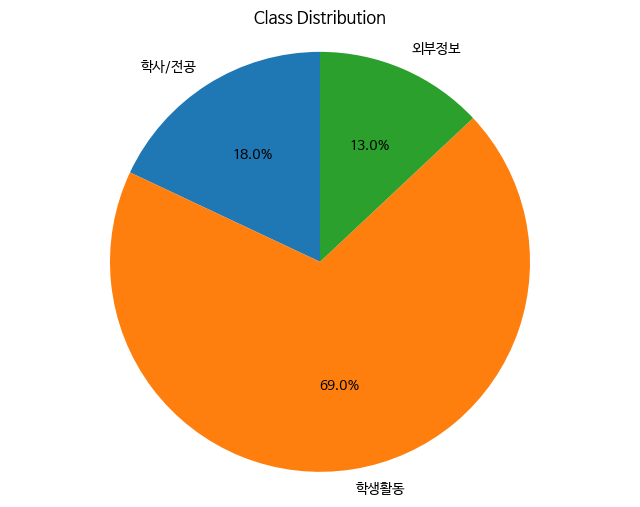

In [33]:
plot_class(ko_df)

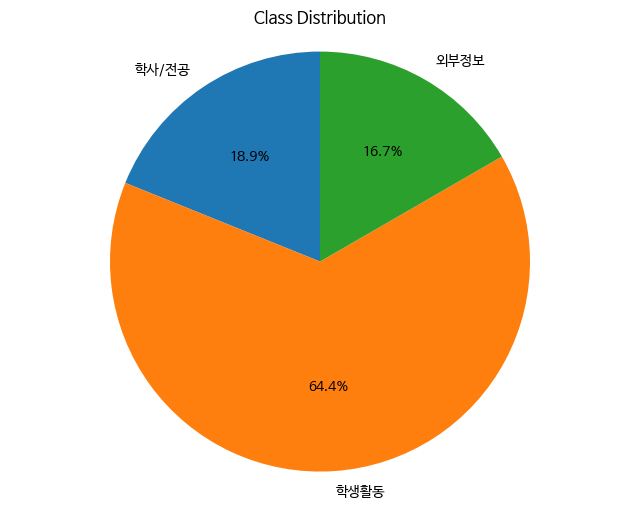

In [34]:
plot_class(law_df)